# 05 Image similarity on the development products
This notebook tests whether product pictures help find similar products. I turned the pictures into vectors (lists of numbers) with two ready-made models, ResNet and CLIP, and scored them against my ratings. The models were used as they are, with no training. Nothing here uses the 20 locked final products.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.rcParams.update(
    {"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREY, ORANGE, GREEN = "#4c78a8", "#c7c7c7", "#f58518", "#54a24b"
pd.set_option("display.width", 170)

results = root / "results"
downloads = pd.read_csv(results / "dev_image_downloads.csv")
speed = json.loads((results / "dev_image_embedding_speed.json").read_text(encoding="utf-8"))
coverage = json.loads((results / "dev_image_search_coverage.json").read_text(encoding="utf-8"))
board = pd.read_csv(results / "dev_image_scoreboard.csv").set_index("method")
pairs = pd.read_csv(results / "dev_image_pairwise.csv")
print("loaded the saved results")

loaded the saved results


## 1. The pictures
I downloaded the first picture of each of the 30 development products and of the results I had rated before. Pictures stay on my computer and are not in Git.

In [2]:
ok = int(downloads["ok"].sum())
print(f"{len(downloads)} products needed a picture: {ok} downloaded, {len(downloads) - ok} failed")
print(downloads.loc[~downloads["ok"], "error"].value_counts().to_string())
print(f"downloaded size: {downloads['bytes'].sum() / 1e6:.0f} MB")

712 products needed a picture: 708 downloaded, 4 failed
error
http_404        3
no_image_url    1
downloaded size: 19 MB


### What this shows
Almost every picture downloaded. Three links no longer work (error 404) and one product has no picture link. All 708 pictures that downloaded could be opened.

## 2. Turning pictures into vectors
Each picture becomes a vector. Pictures that look alike get vectors that are close together. ResNet gives 2048 numbers per picture and CLIP gives 512.

In [3]:
rows = [
    {
        "model": name,
        "numbers per picture": speed[name]["dimensions"],
        "pictures": speed[name]["images"],
        "ms per picture": speed[name]["ms_per_image"],
    }
    for name in ("resnet50", "clip")
]
display(pd.DataFrame(rows).set_index("model"))

,numbers per picture,pictures,ms per picture
model,,,
resnet50,2048,708,108.9
clip,512,708,15.4


### What this shows
CLIP was faster in this run. The gap is probably partly ResNet warming up, so I do not read much into the speed yet.

## 3. Scoreboard
For each of the 30 development products, each method returns its 10 most similar products. The score uses my ratings, 0, 1 or 2. **nDCG@10** gives more credit to good results near the top. **Precision@10** is the share of the top 10 that I rated 1 or 2. The 95% range shows how much the score could move with other products.

In [4]:
table = pd.DataFrame(
    {
        "nDCG@10": board["ndcg_at_10"].round(3),
        "95% range": [
            f"{lo:.2f} to {hi:.2f}"
            for lo, hi in zip(board["ndcg_at_10_low"], board["ndcg_at_10_high"])
        ],
        "Precision@10": board["precision_at_10"].round(2),
    }
).sort_values("nDCG@10", ascending=False)
display(table)

,nDCG@10,95% range,Precision@10
method,,,
image_clip,0.695,0.62 to 0.77,0.74
baseline,0.681,0.59 to 0.77,0.74
image_resnet,0.569,0.47 to 0.66,0.63
title_only,0.545,0.45 to 0.65,0.55
attributes_only,0.445,0.36 to 0.53,0.62


### What this shows
CLIP and the text baseline have almost the same score, and ResNet is lower. The baseline here is 0.68, not the 0.72 of notebook 04, because the answer key now also contains my ratings of the new image results.

## 4. Are the differences real or luck?
For each pair of methods, the difference in nDCG@10 on the same products, with a 95% range. If the range crosses zero, the difference could be luck.

In [5]:
wanted = [("image_clip", "baseline"), ("image_clip", "image_resnet"), ("baseline", "image_resnet")]
rows = []
for a, b in wanted:
    hit = pairs[
        ((pairs["first"] == a) & (pairs["second"] == b))
        | ((pairs["first"] == b) & (pairs["second"] == a))
    ].iloc[0]
    sign = 1 if hit["first"] == a else -1
    mean, lo, hi = (
        sign * hit["ndcg_difference"],
        sorted([sign * hit["low"], sign * hit["high"]])[0],
        sorted([sign * hit["low"], sign * hit["high"]])[1],
    )
    rows.append(
        {
            "comparison": f"{a} minus {b}",
            "difference": f"{mean:+.3f}",
            "95% range": f"{lo:+.3f} to {hi:+.3f}",
            "verdict": "real" if lo > 0 or hi < 0 else "could be luck",
        }
    )
display(pd.DataFrame(rows).set_index("comparison"))

,difference,95% range,verdict
comparison,,,
image_clip minus baseline,+0.014,-0.085 to +0.107,could be luck
image_clip minus image_resnet,+0.126,+0.052 to +0.205,real
baseline minus image_resnet,+0.112,+0.016 to +0.215,real


### What this shows
CLIP against the baseline could be luck, so I call it a tie. CLIP is clearly better than ResNet, and the baseline is clearly better than ResNet.

## 5. How far to trust this

In [6]:
for name in ("resnet50", "clip"):
    c = coverage["models"][name]
    print(
        f"{name}: {c['results_total']} results, {c['already_rated']} already rated before, the rest rated now"
    )
print(
    "Image search only looked at the 708 downloaded pictures. Text search looked at all 30,000 products."
)

resnet50: 300 results, 122 already rated before, the rest rated now
clip: 300 results, 150 already rated before, the rest rated now
Image search only looked at the 708 downloaded pictures. Text search looked at all 30,000 products.


- **Small search space.** Image search only looked at 708 pictures, which the text methods had already picked. That helps image search.
- **One rater and 30 products.** Small differences cannot be told apart.
- **Development set only.** The 20 locked final products have not been touched.

## 6. Recorded in MLflow
Both image runs are saved in MLflow with their settings and scores. This is MLflow's comparison page for ResNet and CLIP:

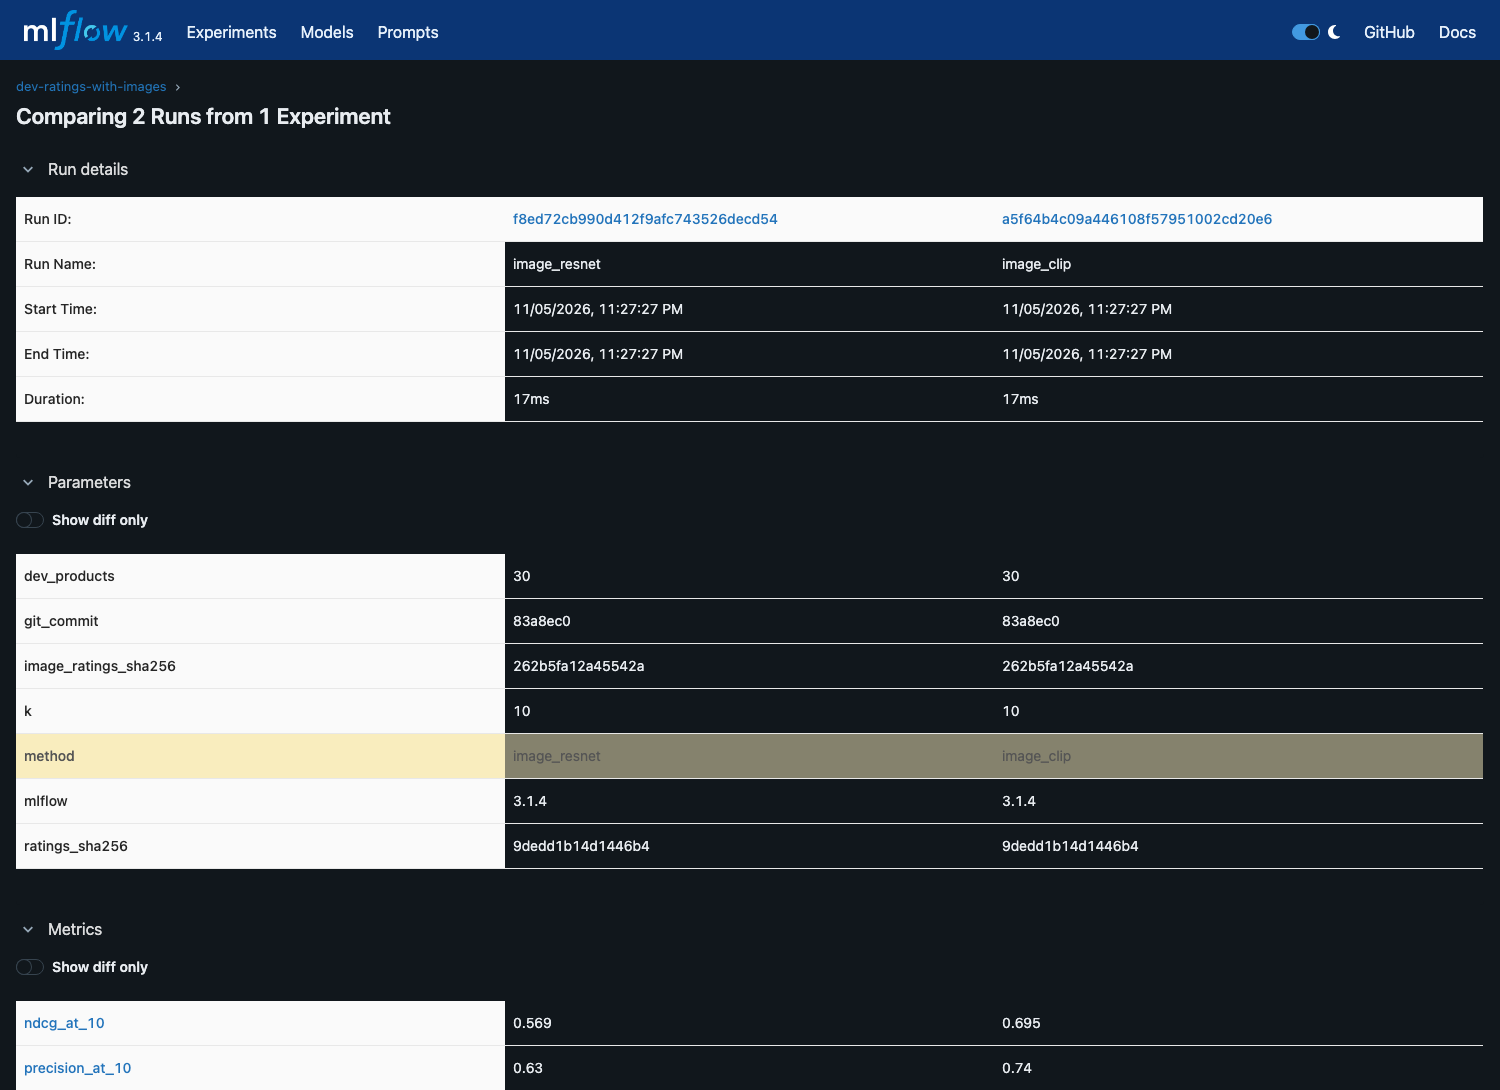

In [7]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_image_runs.png", width=900)

## 7. Conclusion

**Goal:** find out whether product pictures help find similar products.

**What I did.** I turned the product pictures into vectors, which are lists of numbers, with two ready-made models, ResNet and CLIP. Pictures that look alike get vectors that are close together. For my 30 test products, I used those vectors to find the 10 most similar products. I rated the new results myself, so every method is scored with the same ratings.

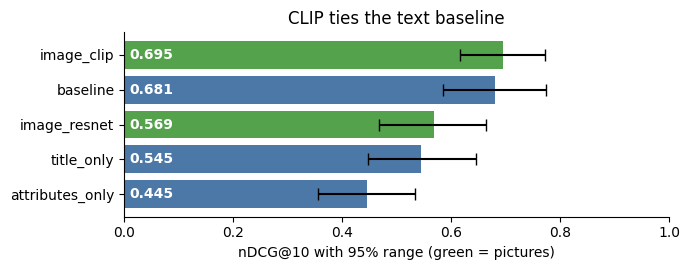

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.8))
order = ["image_clip", "baseline", "image_resnet", "title_only", "attributes_only"]
means = [board.loc[n, "ndcg_at_10"] for n in order]
low = [board.loc[n, "ndcg_at_10"] - board.loc[n, "ndcg_at_10_low"] for n in order]
high = [board.loc[n, "ndcg_at_10_high"] - board.loc[n, "ndcg_at_10"] for n in order]
colours = [GREEN if n.startswith("image") else BLUE for n in order]
ax.barh(order[::-1], means[::-1], xerr=[low[::-1], high[::-1]], color=colours[::-1], capsize=4)
for i, v in enumerate(means[::-1]):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 with 95% range (green = pictures)")
ax.set_title("CLIP ties the text baseline")
plt.tight_layout()
plt.show()

| Method | nDCG@10 | Precision@10 |
|---|---|---|
| CLIP (pictures) | 0.695 | 0.74 |
| Text + attributes (my baseline) | 0.681 | 0.74 |
| ResNet (pictures) | 0.569 | 0.63 |
| Title only | 0.545 | 0.55 |
| Attributes only | 0.445 | 0.62 |

Precision@10 is the share of the top 10 results that I rated 1 or 2.

**What I found**
- CLIP is as good as my best text method. The gap is too small to call a winner.
- CLIP is clearly better than ResNet.
- ResNet is worse than my text method.
- Pictures alone find good matches. Using pictures and text together is worth trying next.

**What I cannot say yet**
- Image search only looked at 708 pictures, which the text methods had already picked. That helps image search, so this is not a perfect comparison.
- I used 30 test products, and one person (me) did all the rating.

**Next.** Test CLIP on all 30,000 pictures, then combine text and CLIP vectors.